Name : Bhalchim Roshani Ramchandra  
Roll No. : 08  
Title : Implement K-Nearest Neighbours’ algorithm on Social network ad dataset. Compute confusion matrix, accuracy, error rate, precision and recall on the given dataset.
Dataset link:https://www.kaggle.com/datasets/rakeshrau/social-network-ads

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

In [2]:
df = pd.read_csv("Social_Network_Ads.csv")
df = df.drop(columns=["User ID", "Gender"], errors="ignore").dropna()

X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

print(df.head())

   Age  EstimatedSalary  Purchased
0   19            19000          0
1   35            20000          0
2   26            43000          0
3   27            57000          0
4   19            76000          0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [4]:
#apply knn
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print("Predictions:", y_pred)

Predictions: [1 1 0 1 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 1 0 0 1 1 0 1 0 0 1 0 1 0 1 0 1 0 0
 0 0 0 1 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 1 0 0 0
 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 0 1 1]


[[59  4]
 [ 3 34]]


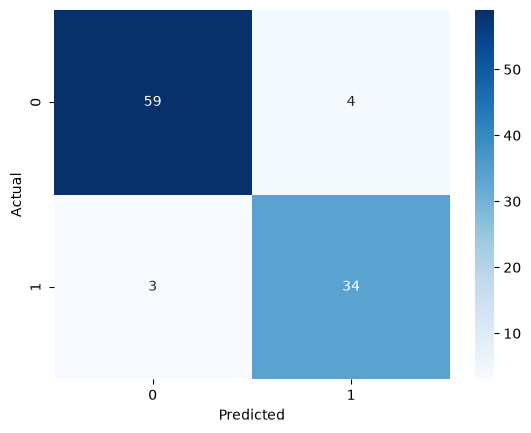

In [5]:
#confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [6]:
#Calculate evaluation metrics
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)
print("Error Rate:", 1 - acc)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))

Accuracy: 0.93
Error Rate: 0.06999999999999995
Precision: 0.8947368421052632
Recall: 0.918918918918919
